#Dataset loading and demonstration

Количество примеров в обучающей выборке: 60000
Количество примеров в тестовой выборке: 10000
Размерность обучающего массива изображений: (60000, 28, 28)
Размерность тестового массива изображений: (10000, 28, 28)
Размерность одного изображения: (28, 28)
Размерность массива меток обучения: (60000,)
Размерность массива меток теста: (10000,)
Тип данных пикселей: uint8
Диапазон значений пикселей: [0, 255]


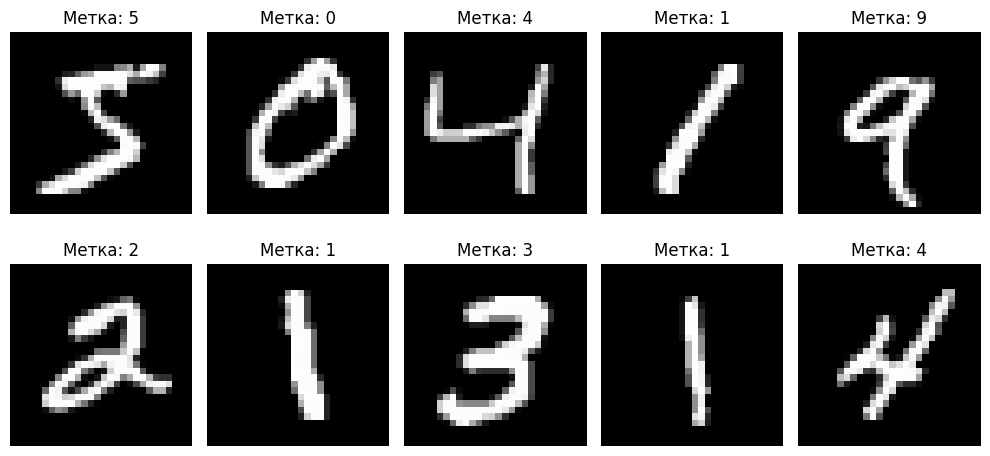

In [ ]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt

url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
file_path = "mnist.npz"

if not os.path.exists(file_path):
    urllib.request.urlretrieve(url, file_path)

with np.load(file_path) as data:
    x_train_raw = data["x_train"]
    y_train_raw = data["y_train"]
    x_test_raw = data["x_test"]
    y_test_raw = data["y_test"]

print(f"Количество примеров в обучающей выборке: {x_train_raw.shape[0]}")
print(f"Количество примеров в тестовой выборке: {x_test_raw.shape[0]}")
print(f"Размерность обучающего массива изображений: {x_train_raw.shape}")
print(f"Размерность тестового массива изображений: {x_test_raw.shape}")
print(f"Размерность одного изображения: {x_train_raw[0].shape}")
print(f"Размерность массива меток обучения: {y_train_raw.shape}")
print(f"Размерность массива меток теста: {y_test_raw.shape}")
print(f"Тип данных пикселей: {x_train_raw.dtype}")
print(f"Диапазон значений пикселей: [{x_train_raw.min()}, {x_train_raw.max()}]")

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_raw[i], cmap="gray")
    ax.set_title(f"Метка: {y_train_raw[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

#Data preprocessing, normalization, reshaping and one-hot encoding

In [ ]:
x_train = x_train_raw.reshape(-1, 28 * 28).astype(np.float32) / 255.0
x_test = x_test_raw.reshape(-1, 28 * 28).astype(np.float32) / 255.0

def to_one_hot(labels, num_classes=10):
    encoded = np.zeros((labels.size, num_classes), dtype=np.float32)
    encoded[np.arange(labels.size), labels] = 1.0
    return encoded

y_train = to_one_hot(y_train_raw)
y_test = to_one_hot(y_test_raw)

print(f"Размерность x_train после предобработки: {x_train.shape}")
print(f"Размерность x_test после предобработки: {x_test.shape}")
print(f"Размерность y_train после one-hot: {y_train.shape}")
print(f"Размерность y_test после one-hot: {y_test.shape}")
print(f"Пример одной метки (цифра {y_train_raw[0]}): {y_train[0]}")

Размерность x_train после предобработки: (60000, 784)
Размерность x_test после предобработки: (10000, 784)
Размерность y_train после one-hot: (60000, 10)
Размерность y_test после one-hot: (10000, 10)
Пример одной метки (цифра 5): [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


#NN implementation

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt

class TwoLayerNet:
    def __init__(self, input_dim=784, hidden_dim=300, output_dim=10, lr=0.1, seed=42):
        np.random.seed(seed)
        self.lr = lr
        self.w1 = np.random.randn(input_dim, hidden_dim).astype(np.float32) * np.sqrt(2.0 / input_dim)
        self.b1 = np.zeros((1, hidden_dim), dtype=np.float32)
        self.w2 = np.random.randn(hidden_dim, output_dim).astype(np.float32) * np.sqrt(2.0 / hidden_dim)
        self.b2 = np.zeros((1, output_dim), dtype=np.float32)

        self.z1 = None
        self.a1 = None
        self.z2 = None
        self.a2 = None

    def _relu(self, z):
        return np.maximum(0.0, z)

    def _relu_derivative(self, z):
        return (z > 0).astype(np.float32)

    def _softmax(self, z):
        shift_z = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(shift_z)
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def forward(self, x):
        self.z1 = np.dot(x, self.w1) + self.b1
        self.a1 = self._relu(self.z1)
        self.z2 = np.dot(self.a1, self.w2) + self.b2
        self.a2 = self._softmax(self.z2)
        return self.a2

    def backward(self, x_batch, y_batch):
        m = x_batch.shape[0]

        delta2 = (self.a2 - y_batch) / m
        dw2 = np.dot(self.a1.T, delta2)
        db2 = np.sum(delta2, axis=0, keepdims=True)

        delta1 = np.dot(delta2, self.w2.T) * self._relu_derivative(self.z1)
        dw1 = np.dot(x_batch.T, delta1)
        db1 = np.sum(delta1, axis=0, keepdims=True)

        self.w2 -= self.lr * dw2
        self.b2 -= self.lr * db2
        self.w1 -= self.lr * dw1
        self.b1 -= self.lr * db1

    def compute_metrics(self, y_pred, y_true):
        eps = 1e-15
        y_pred_clipped = np.clip(y_pred, eps, 1.0 - eps)
        loss = -np.mean(np.sum(y_true * np.log(y_pred_clipped), axis=1))
        error_rate = np.mean(np.argmax(y_pred, axis=1) != np.argmax(y_true, axis=1))
        accuracy = 1.0 - error_rate
        return loss, error_rate, accuracy

    def fit(self, x_train, y_train, epochs=20, batch_size=64):
        num_samples = x_train.shape[0]
        history = {"loss": [], "error": [], "accuracy": [], "time": []}

        for epoch in range(epochs):
            start_time = time.time()

            indices = np.random.permutation(num_samples)
            x_shuffled = x_train[indices]
            y_shuffled = y_train[indices]

            for i in range(0, num_samples, batch_size):
                x_batch = x_shuffled[i : i + batch_size]
                y_batch = y_shuffled[i : i + batch_size]
                self.forward(x_batch)
                self.backward(x_batch, y_batch)

            elapsed_time = time.time() - start_time

            train_preds = self.forward(x_train)
            loss, error, acc = self.compute_metrics(train_preds, y_train)

            history["loss"].append(loss)
            history["error"].append(error)
            history["accuracy"].append(acc)
            history["time"].append(elapsed_time)

            print(
                f"Эпоха {epoch + 1:2d}/{epochs:2d} | "
                f"Время: {elapsed_time:.2f} с | "
                f"Ошибка: {error * 100:.2f}% | "
                f"Точность: {acc * 100:.2f}%"
            )

        return history

    def evaluate(self, x_test, y_test):
        test_preds = self.forward(x_test)
        return self.compute_metrics(test_preds, y_test)

    def predict(self, x):
        preds = self.forward(x)
        return np.argmax(preds, axis=1)

In [ ]:
model = TwoLayerNet(input_dim=784, hidden_dim=300, output_dim=10, lr=0.1, seed=42)

history = model.fit(x_train, y_train, epochs=20, batch_size=64)

_, test_error, test_acc = model.evaluate(x_test, y_test)

print("\n" + "=" * 50)
print(f"Финальная ошибка классификации (Test Error): {test_error * 100:.2f}%")
print(f"Финальная точность (Test Accuracy): {test_acc * 100:.2f}%")
print("=" * 50)

Эпоха  1/20 | Время: 9.38 с | Ошибка: 6.41% | Точность: 93.59%
Эпоха  2/20 | Время: 4.36 с | Ошибка: 4.28% | Точность: 95.72%
Эпоха  3/20 | Время: 4.00 с | Ошибка: 3.22% | Точность: 96.78%
Эпоха  4/20 | Время: 8.48 с | Ошибка: 2.57% | Точность: 97.43%
Эпоха  5/20 | Время: 3.80 с | Ошибка: 2.40% | Точность: 97.60%
Эпоха  6/20 | Время: 5.36 с | Ошибка: 1.84% | Точность: 98.16%
Эпоха  7/20 | Время: 3.73 с | Ошибка: 1.61% | Точность: 98.39%
Эпоха  8/20 | Время: 6.73 с | Ошибка: 1.39% | Точность: 98.61%
Эпоха  9/20 | Время: 3.92 с | Ошибка: 1.17% | Точность: 98.83%
Эпоха 10/20 | Время: 7.93 с | Ошибка: 1.08% | Точность: 98.92%
Эпоха 11/20 | Время: 3.88 с | Ошибка: 0.87% | Точность: 99.13%
Эпоха 12/20 | Время: 6.73 с | Ошибка: 0.85% | Точность: 99.15%
Эпоха 13/20 | Время: 3.88 с | Ошибка: 0.62% | Точность: 99.38%
Эпоха 14/20 | Время: 6.78 с | Ошибка: 0.54% | Точность: 99.46%
Эпоха 15/20 | Время: 3.78 с | Ошибка: 0.55% | Точность: 99.45%
Эпоха 16/20 | Время: 7.06 с | Ошибка: 0.40% | Точность:

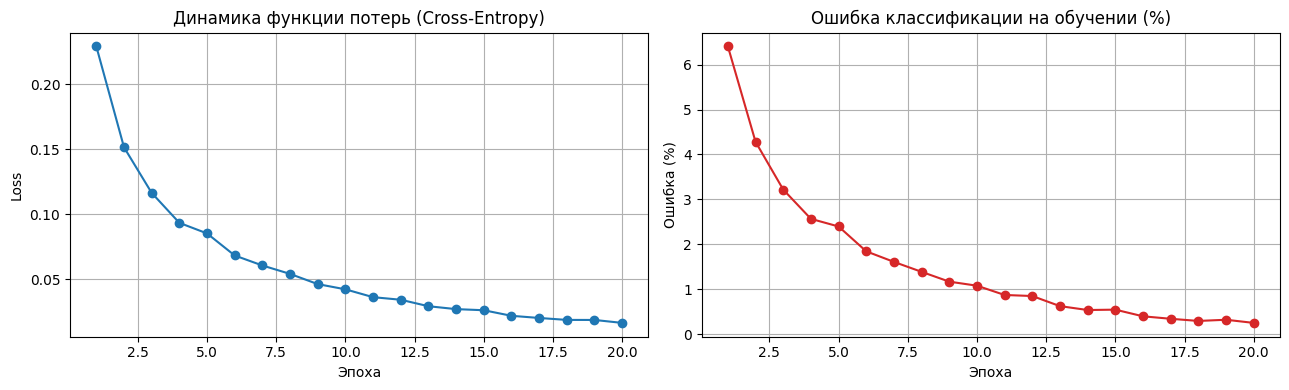

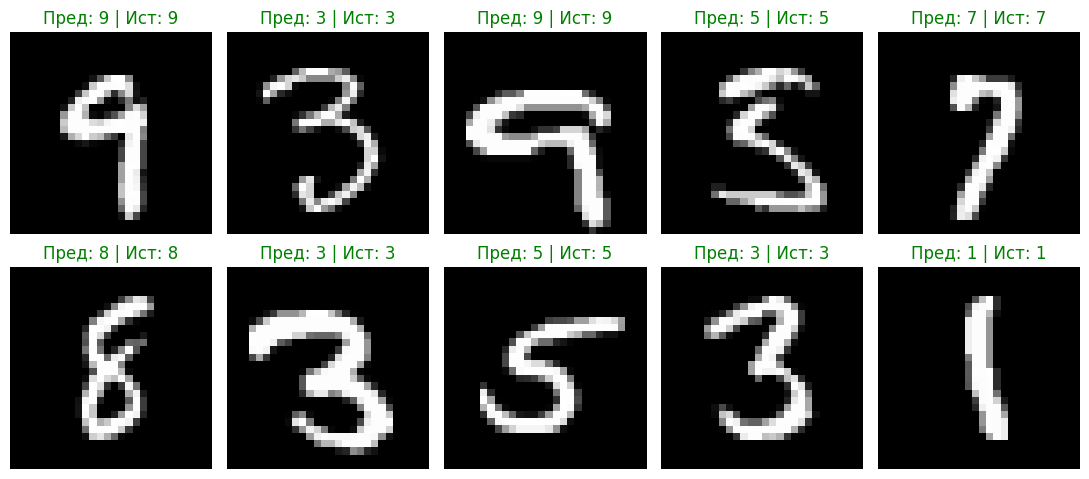

In [ ]:
epochs_range = range(1, len(history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs_range, history["loss"], color="tab:blue", marker="o")
axes[0].set_title("Динамика функции потерь (Cross-Entropy)")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].grid(True)

axes[1].plot(epochs_range, [e * 100 for e in history["error"]], color="tab:red", marker="o")
axes[1].set_title("Ошибка классификации на обучении (%)")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Ошибка (%)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

sample_indices = np.random.choice(len(x_test), size=10, replace=False)
sample_images = x_test[sample_indices]
predicted_labels = model.predict(sample_images)
true_labels = y_test_raw[sample_indices]

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test_raw[sample_indices[i]], cmap="gray")
    pred = predicted_labels[i]
    true = true_labels[i]
    color = "green" if pred == true else "red"
    ax.set_title(f"Пред: {pred} | Ист: {true}", color=color)
    ax.axis("off")

plt.tight_layout()
plt.show()